# Task 1 · Iris Flower Classification

**Objective:** Train classifiers that predict the iris species (*setosa*, *versicolor*, *virginica*) from four physical measurements.

**Stack:** Python, pandas, scikit-learn, matplotlib, seaborn

**Plan**
1. Load data and run EDA
2. Visualise distributions and relationships
3. Discuss which features discriminate best
4. Split 80/20 (stratified)
5. Train 4 classifiers and evaluate each (accuracy, confusion matrix, classification report)
6. Cross-validate, because a 30-row test set is too small to rank models reliably
7. Declare the best model with justification

## 1. Imports and setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.feature_selection import f_classif, mutual_info_classif

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42  # fixed seed so results are reproducible

## 2. Load the dataset
Iris ships inside scikit-learn, so no download is needed.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Replace numeric targets (0/1/2) with readable species names
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")

# Shorter column names make plots easier to read
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
FEATURES = df.columns[:-1].tolist()
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis

In [3]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance:")
print(df["species"].value_counts())

Shape: (150, 5)

Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1

Class balance:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
# Descriptive statistics for all numeric features
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


In [5]:
# Descriptive statistics split by species
df.groupby("species")[FEATURES].agg(["mean", "std"]).round(2)

sepal_length       sepal_width       petal_length        \
                   mean   std        mean   std         mean   std   
species                                                              
setosa             5.01  0.35        3.43  0.38         1.46  0.17   
versicolor         5.94  0.52        2.77  0.31         4.26  0.47   
virginica          6.59  0.64        2.97  0.32         5.55  0.55   

           petal_width        
                  mean   std  
species                       
setosa            0.25  0.11  
versicolor        1.33  0.20  
virginica         2.03  0.27

## 4. Visualisations

### 4.1 Pairplot: feature distributions and relationships by species

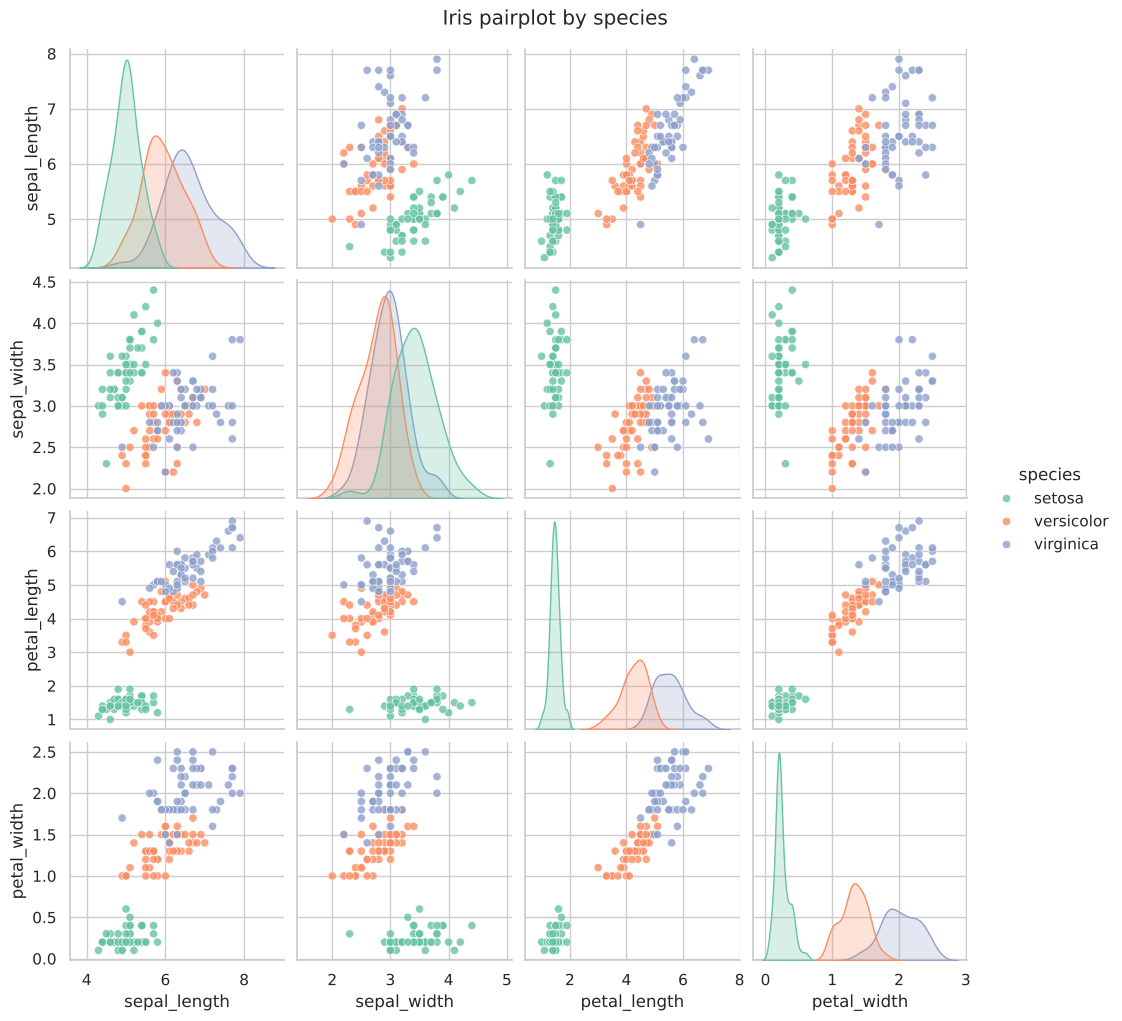

In [6]:
g = sns.pairplot(df, hue="species", diag_kind="kde", palette="Set2",
                 plot_kws={"alpha": 0.8, "s": 35})
g.figure.suptitle("Iris pairplot by species", y=1.02)
plt.show()

### 4.2 Box plots for each feature

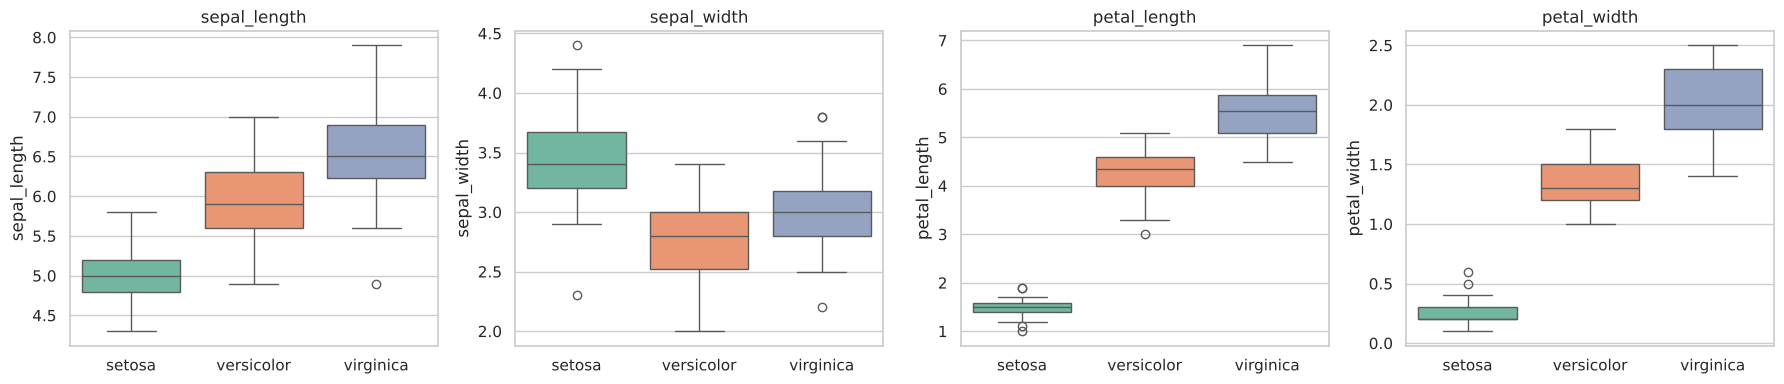

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, feat in zip(axes, FEATURES):
    sns.boxplot(data=df, x="species", y=feat, palette="Set2", ax=ax)
    ax.set_title(feat)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

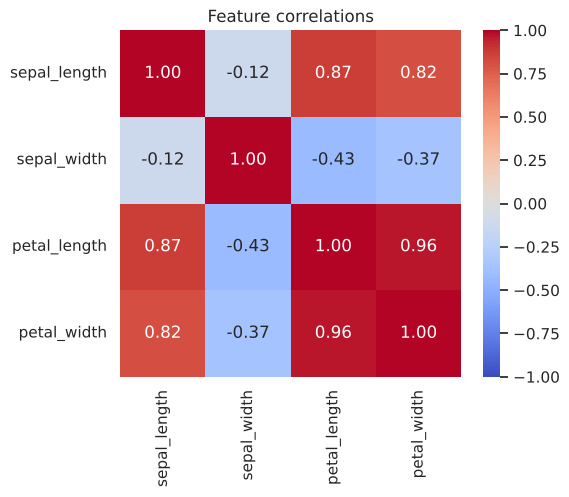

In [8]:
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature correlations")
plt.show()

## 5. Feature selection: which features discriminate best?
Three independent lenses: ANOVA F-score (between-class vs within-class variance), mutual information, and random-forest importance.

In [9]:
X_all, y_all = df[FEATURES], df["species"]

f_scores, _ = f_classif(X_all, y_all)
mi_scores = mutual_info_classif(X_all, y_all, random_state=RANDOM_STATE)
rf_imp = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_all, y_all).feature_importances_

feat_table = pd.DataFrame({
    "ANOVA_F": f_scores,
    "mutual_info": mi_scores,
    "RF_importance": rf_imp,
}, index=FEATURES).round(3).sort_values("ANOVA_F", ascending=False)
feat_table

,ANOVA_F,mutual_info,RF_importance
petal_length,1180.161,0.993,0.455
petal_width,960.007,0.986,0.417
sepal_length,119.265,0.511,0.107
sepal_width,49.160,0.299,0.021


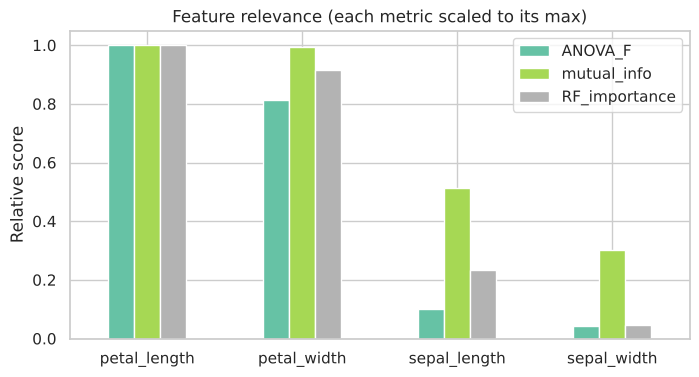

In [10]:
# Normalise each score to 0-1 so the three methods are comparable on one chart
norm = feat_table / feat_table.max()
norm.plot(kind="bar", figsize=(8, 4), colormap="Set2")
plt.title("Feature relevance (each metric scaled to its max)")
plt.ylabel("Relative score")
plt.xticks(rotation=0)
plt.show()

### Discussion: which features are most discriminative?

All three scoring methods rank the features identically: **petal length > petal width >> sepal length > sepal width**.

| Feature | ANOVA F | Mutual info | RF importance |
|---|---|---|---|
| petal_length | 1180 | 0.99 | 0.455 |
| petal_width | 960 | 0.99 | 0.417 |
| sepal_length | 119 | 0.51 | 0.107 |
| sepal_width | 49 | 0.30 | 0.021 |

What the plots and group statistics show:

- **Setosa is separable by petal size alone.** Its mean petal length is about 1.5 cm vs 4.3 cm (versicolor) and 5.6 cm (virginica), a gap many standard deviations wide with no overlap in the box plots.
- **The only real difficulty is versicolor vs virginica.** Their petal measurements are adjacent and overlap in the boundary region, and this is where every misclassification in the results below occurs.
- **Sepal width is the weakest feature.** It carries a little information (setosa tends to have wider sepals) but versicolor and virginica overlap heavily on it.
- **Petal length and petal width are strongly correlated** (see heatmap), so they carry largely redundant information. Using just those two gets most of the way there, but the sepal features still add a small amount of signal at the versicolor/virginica boundary, so this notebook keeps all four.
- The dataset has 1 exact duplicate row. With 150 rows this is negligible, so it was left in.

## 6. Train / test split (80/20)
`stratify=y` keeps the 1/3-1/3-1/3 class ratio in both sets. Without it, a 30-row test set can easily end up with skewed classes.

In [11]:
X = df[FEATURES]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTest class counts:")
print(y_test.value_counts())

Train: (120, 4) | Test: (30, 4)

Test class counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 7. Train the classifiers
Distance- and gradient-based models (Logistic Regression, KNN) are wrapped in a pipeline with `StandardScaler`, and the scaler is fitted on training data only, which avoids leakage. Tree models don't need scaling.

In [12]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
print("Trained:", ", ".join(models))

Trained: Logistic Regression, K-Nearest Neighbours, Decision Tree, Random Forest


## 8. Evaluate each model on the held-out test set

In [13]:
labels = list(iris.target_names)
test_results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    test_results[name] = acc
    print("=" * 62)
    print(f"{name}  |  test accuracy = {acc:.4f}")
    print("=" * 62)
    print("Confusion matrix (rows = true, cols = predicted):")
    print(pd.DataFrame(confusion_matrix(y_test, y_pred, labels=labels),
                       index=[f"true_{l}" for l in labels],
                       columns=[f"pred_{l}" for l in labels]))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, target_names=labels, digits=3))

Logistic Regression  |  test accuracy = 0.9333
Confusion matrix (rows = true, cols = predicted):
                 pred_setosa  pred_versicolor  pred_virginica
true_setosa               10                0               0
true_versicolor            0                9               1
true_virginica             0                1               9

Classification report:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

K-Nearest Neighbours  |  test accuracy = 0.9333
Confusion matrix (rows = true, cols = predicted):
                 pred_setosa  pred_versicolor  pred_virginica
true_setosa               10                0               0
true_versicolor            0

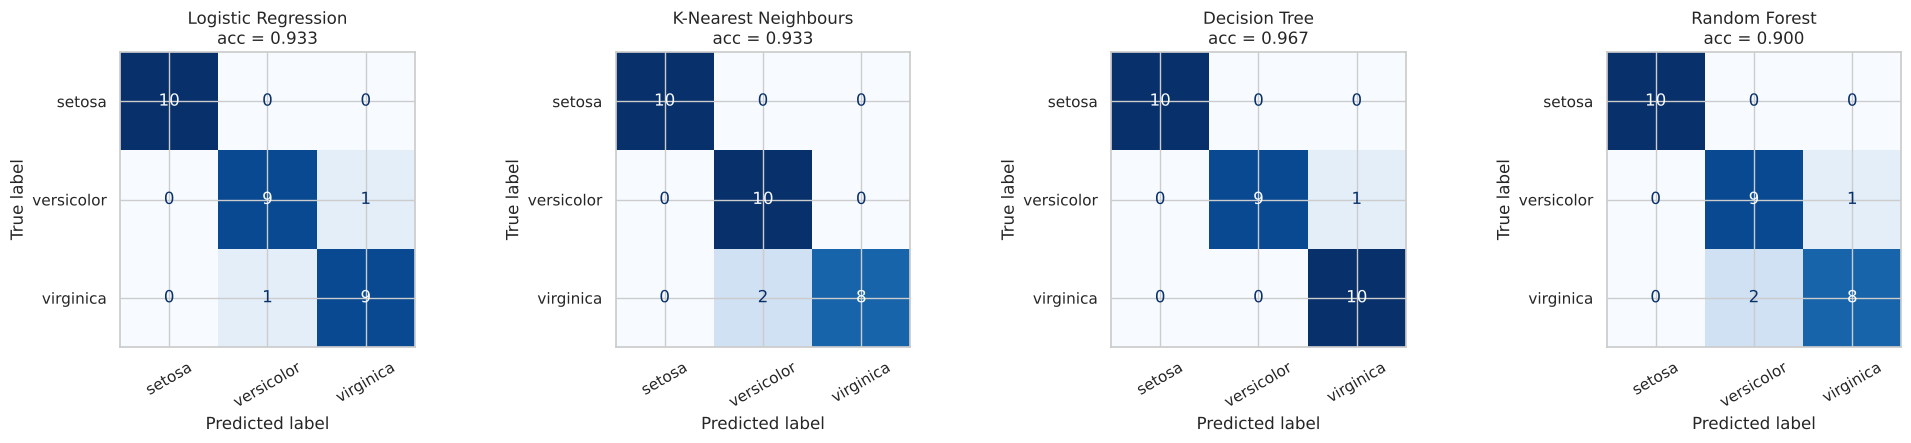

In [14]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=labels,
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nacc = {test_results[name]:.3f}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 9. Cross-validation: a more reliable comparison
The test set has only 30 flowers, so one misclassification moves accuracy by about 3.3 points. Repeated stratified 5-fold CV (10 repeats = 50 fits per model) gives a steadier estimate and a spread we can use to judge whether differences are real.

In [15]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({
        "model": name,
        "cv_mean": scores.mean(),
        "cv_std": scores.std(),
        "test_acc": test_results[name],
    })

summary = pd.DataFrame(cv_rows).set_index("model").sort_values("cv_mean", ascending=False).round(4)
summary

,cv_mean,cv_std,test_acc
model,,,
Logistic Regression,0.9533,0.0346,0.9333
K-Nearest Neighbours,0.9513,0.0277,0.9333
Random Forest,0.9500,0.0342,0.9000
Decision Tree,0.9400,0.0371,0.9667


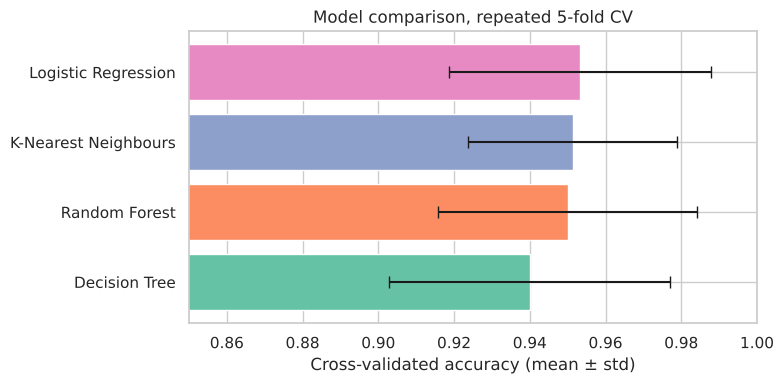

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(summary.index[::-1], summary["cv_mean"][::-1], xerr=summary["cv_std"][::-1],
        color=sns.color_palette("Set2", len(summary)), capsize=4)
ax.set_xlim(0.85, 1.0)
ax.set_xlabel("Cross-validated accuracy (mean ± std)")
ax.set_title("Model comparison, repeated 5-fold CV")
plt.tight_layout()
plt.show()

## 10. Best model

In [17]:
best_name = summary["cv_mean"].idxmax()
print(f"Best model by cross-validated accuracy: {best_name}")
print(f"  CV accuracy : {summary.loc[best_name, 'cv_mean']:.4f} ± {summary.loc[best_name, 'cv_std']:.4f}")
print(f"  Test accuracy: {summary.loc[best_name, 'test_acc']:.4f}")

# How close is the runner-up, in units of standard deviation?
ranked = summary["cv_mean"].sort_values(ascending=False)
gap = ranked.iloc[0] - ranked.iloc[1]
print(f"\nGap to runner-up ({ranked.index[1]}): {gap:.4f}  "
      f"(~{gap / summary.loc[best_name, 'cv_std']:.2f} std of the winner's CV scores)")

Best model by cross-validated accuracy: Logistic Regression
  CV accuracy : 0.9533 ± 0.0346
  Test accuracy: 0.9333

Gap to runner-up (K-Nearest Neighbours): 0.0020  (~0.06 std of the winner's CV scores)


### Verdict

**Best model: Logistic Regression** (highest repeated-CV accuracy, about 95.3%).

**Read this before trusting the ranking.** The four models are statistically tied. Their CV means span only about 1.3 points (94.0% to 95.3%) while each model's fold-to-fold standard deviation is about 3 points. The winner leads the runner-up (KNN) by 0.2 points, a fraction of one standard deviation. On this dataset, picking a "winner" is a tie-break, not a finding.

Why Logistic Regression is the sensible tie-break:

1. **Best CV mean**, and it is evaluated on 50 train/test fits per model rather than on 30 flowers once.
2. **The single 80/20 split is misleading.** Decision Tree scored highest on the test split (96.7%) but lowest in CV (94.0%). That is a one-flower difference on 30 rows, not evidence the tree is better.
3. **Simple, fast and interpretable.** Linear coefficients can be inspected, and it outputs usable class probabilities. The boundary between these species is close to linear, so a more flexible model has little to gain.
4. **Low variance risk.** Unlike an unpruned tree or forest, it is not prone to fitting noise in 120 training rows.

Limitations: only 150 samples, one dataset, default-ish hyperparameters (no tuning), and the numbers quoted in this markdown cell come from `RANDOM_STATE = 42`. Changing the seed will move individual scores slightly.

## 11. Quick demo: predicting a new flower

In [18]:
best_model = models[best_name]
new_flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=FEATURES)
print("Input:", new_flower.iloc[0].to_dict())
print("Predicted species:", best_model.predict(new_flower)[0])
if hasattr(best_model, "predict_proba"):
    probs = best_model.predict_proba(new_flower)[0]
    print({str(c): round(float(p), 3) for c, p in zip(best_model.classes_, probs)})

Input: {'sepal_length': 5.9, 'sepal_width': 3.0, 'petal_length': 5.1, 'petal_width': 1.8}
Predicted species: virginica
{'setosa': 0.004, 'versicolor': 0.314, 'virginica': 0.682}
